# Open-book quiz · Lectures 14–17

**先查这页。** 用 Ctrl/Cmd + F 搜 `__sub__`、`is None`、`@classmethod`、`iloc`、`apply`、`query` 或 `legend`。下面的例子可以从上到下运行，练习 CSV 路径单独列在最后。

| 考到什么 | 直接用什么 |
|---|---|
| 让 `f1 - f2` 能运行 | `__sub__(self, other)`：先创建结果 → `result.reduce()` → `return result` |
| 在限制内修改对象 | 先 `assert` 验证输入，计算新值后交给 setter |
| 跳过已配对的人 | `if student.get_partner() is not None: continue` |
| 查找第一个合格搭档 | 内层循环从头找，双方都合格才配对，随后 `break` |
| 子类覆盖父类方法 | 用**完全相同的方法名**，如 `set_stamina`；`super().method(...)` 可调用父类版本 |
| 修改全班共享的设置 | `@classmethod` + `def method(cls, value)` + `cls.setting = value` |
| 按位置取第 28 到 32 行 | `df.iloc[28:33, :]`，右端不包含；`.loc` 用标签 |
| 先排序，再取前 3 个 | `df.sort_values(by="weight", ascending=True).iloc[:3, :]` |
| 对一列逐个值用函数 | `result = df["column"].apply(function_name)`，函数名后不加括号 |
| 用两个条件筛选 | `df.query("col1 >= 8 and col2 == 5")`，整个条件放进引号 |
| 比例显示为百分比 | `f"{len(group) / n:.2%}"`；`:.2%` 已经会乘以 100 |
| 题目要求 display | 把 `display(result)` 放在**算完之后** |

## Lecture 14 · Classes, objects, and dunder methods

- `self.num = num` 把参数保存到**当前对象**。`a = Fraction(3, 4)` 自动初始化，`a.reduce()` 会把 `a` 自动传给 `self`。
- **属性**用 `a.num`，**方法调用**用 `a.reduce()`。
- `__str__` 和 `__repr__` 都返回字符串。前者供 `print(a)` 使用，后者提供详细表示，如 `repr(a)`。
- `reduce()` 在原对象上修改属性，默认返回 `None`。二元运算通常创建新对象。

In [1]:
from math import gcd

class Fraction:
    def __init__(self, num, den):
        assert den != 0, "denominator cannot be zero"
        if den < 0:
            num, den = -num, -den
        self.num = num
        self.den = den

    def __str__(self):
        return f"{self.num}/{self.den}"

    def __repr__(self):
        return f"Fraction({self.num}, {self.den})"

    def reduce(self):
        common = gcd(self.num, self.den)
        self.num //= common
        self.den //= common

    def __sub__(self, other):
        new_num = self.num * other.den - self.den * other.num
        new_den = self.den * other.den
        result = Fraction(new_num, new_den)
        result.reduce()
        return result

    def __eq__(self, other):
        return self.num * other.den == other.num * self.den

    def to_float(self):
        return self.num / self.den

    def to_percent(self, ndigits=3):
        return f"{self.to_float():.{ndigits}%}"

a = Fraction(5, 6)
b = Fraction(1, 3)
print(a - b, a, b)                       # 1/2 5/6 1/3
print(Fraction(1, 2) == Fraction(2, 4))   # True
print(a is b)                             # False
print(b.to_percent(1))                    # 33.3%

1/2 5/6 1/3
True
False
33.3%


| 运算 | 方法 | 分数规则（左边 $a/b$，右边 $c/d$） |
|---|---|---|
| `+` / `-` | `__add__` / `__sub__` | $(ad \pm bc)/(bd)$ |
| `*` / `/` | `__mul__` / `__truediv__` | $ac/(bd)$、$ad/(bc)$；除数的分子 $c$ 不能为 0 |
| `==` / `!=` | `__eq__` / `__ne__` | 比较 $ad$ 和 $bc$ |
| `<`, `<=`, `>`, `>=` | `__lt__`, `__le__`, `__gt__`, `__ge__` | 分母为正时，直接用对应符号比较 $ad$ 与 $bc$ |

`==` 检查值是否相等，`is` 检查是否为同一个对象。课上也用欧几里得算法求 GCD：不断做 `m, n = n, m % n`，直到余数为 0。

## Lecture 15 · Getters, setters, and matching objects

`__init__` 里用 `self.students = []` 为每个班创建自己的名单。若 `roster = {"Ana": (7, 6)}`，遍历字典时 `name` 是 key，`skill, minimum = roster[name]` 把 value 解包为 7 和 6。

**注意两种条件和缩进。** `if student.get_partner() is None:` 下面可以写搜索循环。使用提前跳过的写法时，`if student.get_partner() is not None:` 下面写 `continue`。检查自己用 `other is student`。

In [2]:
class Student:
    def __init__(self, name, skill, minimum):
        self.name = name
        self.skill = skill
        self.minimum = minimum
        self.partner = None

    def get_partner(self):
        return self.partner

    def set_partner(self, other):
        self.partner = other
        other.partner = self

    def rate(self, other):
        return other.skill

    def accepts(self, other):
        return self.rate(other) >= self.minimum


class LabSection:
    def __init__(self, roster):
        self.students = []
        for name in roster:
            skill, minimum = roster[name]
            self.students.append(Student(name, skill, minimum))

    def match_partners(self):
        for student in self.students:
            if student.get_partner() is not None:
                continue

            for other in self.students:
                if other is student or other.get_partner() is not None:
                    continue
                if student.accepts(other) and other.accepts(student):
                    student.set_partner(other)
                    break

section = LabSection({"Ana": (7, 6), "Ben": (9, 8), "Cy": (6, 7)})
section.match_partners()
for student in section.students:
    partner = student.get_partner()
    print(student.name, "->", None if partner is None else partner.name)

Ana -> Cy
Ben -> None
Cy -> Ana


**Lecture 原版 `consider()` 和练习的固定门槛不同。** Lecture 的策略是先观察前 `N` 次，记录最高评分 `benchmark` 并返回 `False`。之后用 `rating > benchmark` 决定是否接受。在每轮模拟里，两个人都要分别调用 `consider()`，这样双方都能更新见面次数。最后一轮由班级安排剩余的人配对。

练习题如果写「at least」或「within the maximum gap」，用包含边界的 `>=` 或 `<=`。比较体力差时用 `abs(a - b)`。**先出现的合格候选人**就是答案，因此成功后要 `break`。

**修改状态时用 setter。** Practice quiz 的 `log_run` 先验证分数，再更新计数，用 `min` 限制新体力，最后调用 `self.set_stamina()`。

In [3]:
class Runner:
    def __init__(self, stamina):
        self.set_stamina(stamina)
        self.num_runs = 0

    def get_stamina(self):
        return self.stamina

    def set_stamina(self, value):
        assert 0 <= value <= 100, "stamina must be between 0 and 100"
        self.stamina = value

    def log_run(self, score):
        assert 0 <= score <= 100, "score must be between 0 and 100"
        self.num_runs += 1
        new_stamina = self.get_stamina() + score / 10
        self.set_stamina(min(new_stamina, 100))

runner = Runner(95)
runner.log_run(80)
print(runner.get_stamina(), runner.num_runs)  # 100 1

100 1


## Lecture 16 · Class variables, inheritance, and class methods

- **Composition（组合）**：`LabSection` 有一个 `Student` 对象列表。
- **Inheritance（继承）**：`StudyGroupStudent` 是一种 `Student`，可以使用父类的方法。
- **Instance variable** 如 `self.skill`，各对象分别保存。**Class variable** 如 `bonus = 2`，写在 class 里、方法外，供所有实例共享。
- **Override（覆盖）** 要同名。测试调用 `set_stamina()`，子类也必须定义 `set_stamina()`。如果子类允许更高上限，就在子类 setter 里按新的上限验证。
- `isinstance(obj, Student)` 包括子类对象。类方法的 `cls` 是调用它的类，`self` 是实例。

In [4]:
class StudyGroupStudent(Student):
    bonus = 2

    def rate(self, other):
        rating = super().rate(other)
        if isinstance(other, StudyGroupStudent):
            rating += self.bonus
        return rating

    @classmethod
    def set_bonus(cls, value):
        assert 0 <= value <= 5, "bonus must be between 0 and 5"
        cls.bonus = value

ana = StudyGroupStudent("Ana", 7, 6)
ben = StudyGroupStudent("Ben", 6, 6)
print(ana.rate(ben))  # 8

StudyGroupStudent.set_bonus(4)
print(ana.rate(ben))  # 10
print(ben.skill)     # 6，原始能力仍然是 6

8
10
6


如果子类自己写了 `__init__`，可以用 `super().__init__(name, skill, minimum)` 初始化父类属性，再添加自己的属性。父类方法里的 `self.rate(other)` 会调用当前对象对应的版本，因此上面的子类也可以复用 `accepts()`。

**Lab 08 补充。** 方法链依赖每一步的返回值。修改对象后写 `return self`，下一步就能继续用同一个对象。像 `predict()` 或 `to_float()` 这种方法，返回的是题目要的预测值或数值。

## Lecture 17 · Pandas

### 读表、看列名、选行列、排序

| 写法 | 结果 |
|---|---|
| `pd.read_csv("quiz_data/features.csv")` | 从当前工作目录下的相对路径读入 DataFrame |
| `display(df.head())` | 显示前 5 行 |
| `len(df)` / `df.shape` | 行数 / `(行数, 列数)` |
| `df.columns` / `list(df.columns)` | 列名 Index / 列名列表 |
| `df["weight"]` / `df[["weight"]]` | Series / DataFrame |
| `df.loc[10, "weight"]` | 行标签 10 的 weight |
| `df.iloc[0, 0]` | 当前第一个位置的值 |
| `df.iloc[1:4, 2:5]` | 位置 1、2、3 的行和位置 2、3、4 的列 |
| `df.loc[1:4]` | 按标签切片，在有序整数标签下包含标签 4 |
| `df.iloc[-5:, :]` | 最后 5 行 |

`list(df.columns).index("weight")` 用列名找位置，`df.columns[4]` 用位置找列名。排序会保留原有行标签，所以排序后取「前几行」用 `.iloc` 或 `.head()`。

In [5]:
import numpy as np
import pandas as pd

cars = pd.DataFrame({
    "weight": [3500, 2200, 2800, 2400],
    "acceleration": [12.0, 18.0, 15.0, 16.0],
    "vehicle_id": ["A", "B", "C", "D"],
}, index=[10, 20, 30, 40])

subset = cars.iloc[0:4, 0:3]
sorted_cars = subset.sort_values(by="weight", ascending=True)
lightest_three = sorted_cars.iloc[:3, :]
display(lightest_three)  # 原行标签 20、40、30

,weight,acceleration,vehicle_id
20,2200,18.0,B
40,2400,16.0,D
30,2800,15.0,C


### `.query()`、`.apply()`、新增列

`.query()` 接收**一个条件字符串**。外部 Python 变量加 `@`，有空格或括号的列名用反引号，比较文字时给文字加引号。

`.apply(function_name)` 返回一个 Series。若题目要求 **define a Series named `speed_mps`**，就写 `speed_mps = ...`。若题目要求**新增指定名字的列**，就写 `df["Exact Name"] = ...`。

In [ ]:
vehicles = pd.DataFrame({
    "Speed (mph)": [30, 45, 60, 72],
    "Mass (kg)": [1200, 1500, 1800, 1300],
    "Type": ["Car", "Car", "Truck", "Car"],
})

def mph_to_mps(speed):
    return speed * 1609.34 / 3600

speed_mps = vehicles["Speed (mph)"].apply(mph_to_mps)
vehicles["Momentum (kg m/s)"] = vehicles["Mass (kg)"] * speed_mps
vehicles["Kinetic Energy (J)"] = 0.5 * vehicles["Mass (kg)"] * speed_mps**2
display(vehicles.head())

threshold = 40
fast_cars = vehicles.query("`Speed (mph)` >= @threshold and Type == 'Car'")
display(fast_cars)


,Speed (mph),Mass (kg),Type,Momentum (kg m/s),Kinetic Energy (J)
0,30,1200,Car,16093.400,107915.634817
1,45,1500,Car,30175.125,303512.722922
2,60,1800,Truck,48280.200,647493.808900
3,72,1300,Car,41842.840,673393.561256


,Speed (mph),Mass (kg),Type,Momentum (kg m/s),Kinetic Energy (J)
1,45,1500,Car,30175.125,303512.722922
3,72,1300,Car,41842.840,673393.561256


### 随机分组和百分比

`size=n` 为每一行生成一个随机数。三个区间用 `< 0.25`、`>= 0.25 and < 0.75`、`>= 0.75`，边界不会重复分组。使用 `:.2%` 格式化比例。

In [7]:
players = pd.DataFrame({"player_id": np.arange(1000)})
n = len(players)
players["draw"] = np.random.uniform(0, 1, size=n)

group_a = players.query("draw < 0.25")
group_b = players.query("draw >= 0.25 and draw < 0.75")
group_c = players.query("draw >= 0.75")

print(f"A: {len(group_a) / n:.2%}")
print(f"B: {len(group_b) / n:.2%}")
print(f"C: {len(group_c) / n:.2%}")

A: 25.20%
B: 49.40%
C: 25.40%


### 按类别画图

`pd.unique(df["Type"])` 给出不重复的类别。循环里用 `@category` 筛当前组，再画该组。给每组的点传 `label=category`，最后的 `plt.legend()` 会显示每种颜色对应的类别。

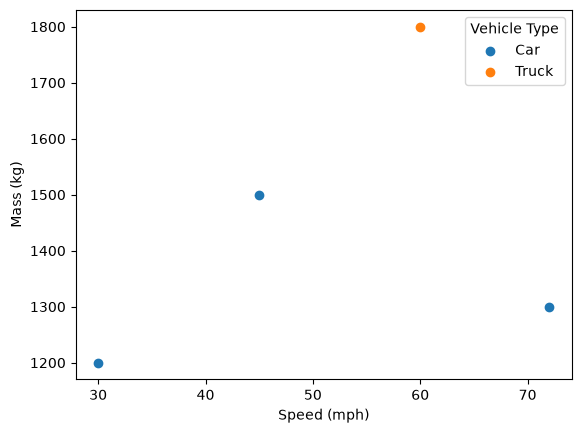

In [8]:
import matplotlib.pyplot as plt

for category in pd.unique(vehicles["Type"]):
    subset = vehicles.query("Type == @category")
    plt.scatter(subset["Speed (mph)"], subset["Mass (kg)"], label=category)

plt.xlabel("Speed (mph)")
plt.ylabel("Mass (kg)")
plt.legend(title="Vehicle Type")
plt.show()

## Practice quiz · 路径和常用写法

| CSV | 答题时用到的写法 |
|---|---|
| `quiz_data/fifa23_players_basic.csv` | `np.random.uniform(0, 1, size=n)`，用 `.query()` 分组 |
| `quiz_data/features.csv` | `df.iloc[28:33, 4:7]` 选原 practice 的 5 辆车；新 practice 的行切片是 `36:46` |
| `quiz_data/speed_mass.csv` | 列名是 `"Speed (mph)"` 和 `"Mass (kg)"`，保留大小写、空格和括号 |

题目如果给了输出名、方法名、参数名或列名，就照抄。示例输出正确也要确认具体要求，例如用了 setter、返回了新对象，或真的显示了结果。